# PART IV


In [1]:
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt, seaborn as sns, numpy as np, time
from sklearn.metrics import precision_recall_fscore_support, classification_report
from itertools import cycle
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

## LOAD, PREPROCESS, ANALYZE, VISUALIZE     

In [4]:
data_dir = "cnn_dataset"

In [5]:
IMGdata = datasets.ImageFolder(data_dir, transform=transform)
train_len = int(0.8 * len(IMGdata))
val_len   = int(0.1 * len(IMGdata))
test_len  = len(IMGdata) - train_len - val_len
train, val, test = torch.utils.data.random_split(IMGdata, [train_len, val_len, test_len])

In [6]:
train_len = int(0.8*len(train))
val_len   = len(train) - train_len
train, val = torch.utils.data.random_split(train, [train_len, val_len])

In [7]:
train1 = DataLoader(train, batch_size=64, shuffle=True)
val1   = DataLoader(val, batch_size=64, shuffle=False)
test1  = DataLoader(test, batch_size=64, shuffle=False)

In [8]:
classes = len(IMGdata.classes)
print("Classes:", classes)

Classes: 36


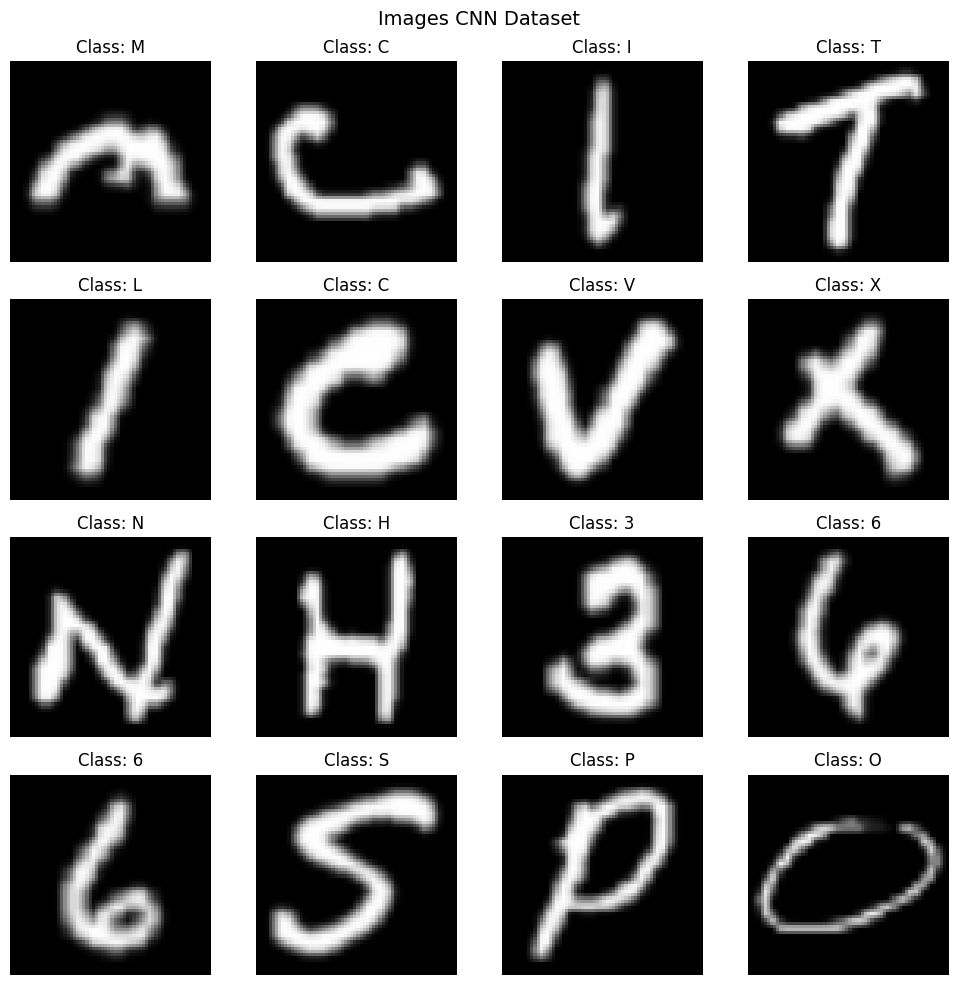

In [9]:
images, labels = next(iter(train1))
images = images * 0.5 + 0.5 
plt.figure(figsize=(10, 10))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    img = np.transpose(images[i].numpy(), (1, 2, 0)) 
    plt.imshow(img)
    plt.title(f"Class: {IMGdata.classes[labels[i]]}")
    plt.axis("off")
plt.suptitle("Images CNN Dataset", fontsize=14)
plt.tight_layout()
plt.show()

## IMPLEMENT THE VGG-13

In [10]:
cfg = [64, 64, 'M', 128, 128, 'M', 256, 256, 'M', 512, 512, 'M']
class VGG13(nn.Module):
    def __init__(self, num_classes):
        super(VGG13, self).__init__()
        self.features = self._make_layers(cfg)
        self.classifier = nn.Sequential(
            nn.Linear(512*4*4, 4096), nn.ReLU(True), nn.Dropout(0.5),
            nn.Linear(4096, 4096), nn.ReLU(True), nn.Dropout(0.5),
            nn.Linear(4096, classes)
        )
    def _make_layers(self, cfg):
        layers = []; in_ch = 3
        for x in cfg:
            if x == 'M':
                layers += [nn.MaxPool2d(kernel_size=2, stride=2)]
            else:
                layers += [nn.Conv2d(in_ch, x, 3, padding=1),
                           nn.BatchNorm2d(x),
                           nn.ReLU(inplace=True)]
                in_ch = x
        return nn.Sequential(*layers)
    def forward(self, x):
        out = self.features(x)
        out = torch.flatten(out, 1)
        out = self.classifier(out)
        return out

model = VGG13(classes).to(device)
print(model)

VGG13(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(128, 2

In [19]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0008, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.7)

## TRAINING THE MODEL 

In [12]:
def train(model, train1, val1, epochs=10):
    best_acc = 0; tr_hist, val_hist = [], []
    for e in range(epochs):
        model.train(); correct = 0; total = 0
        for x, y in train1:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward(); optimizer.step()
            _, p = torch.max(out, 1)
            correct += (p==y).sum().item(); total += y.size(0)
        train_acc = correct/total
        model.eval(); v_correct = 0; v_total = 0
        with torch.no_grad():
            for x, y in val1:
                x, y = x.to(device), y.to(device)
                out = model(x)
                _, p = torch.max(out, 1)
                v_correct += (p==y).sum().item(); v_total += y.size(0)
        val_acc = v_correct/v_total
        scheduler.step()
        tr_hist.append(train_acc); val_hist.append(val_acc)
        print(f"Epoch {e+1}: Train={train_acc:.3f}, Val={val_acc:.3f}")
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), "a2_part4_weights_pranayla_vpamulap.pkl")
    return tr_hist, val_hist, best_acc

start=time.time()
train_hist, val_hist, best_val = train(model, train1, val1, epochs=10)
print(f"\nBest Validation Accuracy: {best_val*100:.2f}%")
print("Training time:", round((time.time()-start)/60,2), "mins")

Epoch 1: Train=0.521, Val=0.835
Epoch 2: Train=0.763, Val=0.862
Epoch 3: Train=0.829, Val=0.885
Epoch 4: Train=0.878, Val=0.897
Epoch 5: Train=0.893, Val=0.903
Epoch 6: Train=0.899, Val=0.908
Epoch 7: Train=0.909, Val=0.907
Epoch 8: Train=0.913, Val=0.915
Epoch 9: Train=0.914, Val=0.912
Epoch 10: Train=0.923, Val=0.920

Best Validation Accuracy: 92.01%
Training time: 321.2 mins


## EVALUATING THE PERFORMANCE OF THE MODEL 

In [14]:
model.load_state_dict(torch.load("a2_part4_weights_pranayla_vpamulap.pkl"))
model.eval(); preds, trues = [], []
with torch.no_grad():
    for x, y in test1:
        x, y = x.to(device), y.to(device)
        out = model(x)
        _, p = torch.max(out, 1)
        preds += p.cpu().tolist(); trues += y.cpu().tolist()
acc = accuracy_score(trues, preds)*100
print("Test Accuracy:", acc)
precision, recall, f1, _ = precision_recall_fscore_support(trues, preds, average='weighted')
print(f"Precision: {precision*100:.2f}%")
print(f"Recall:    {recall*100:.2f}%")
print(f"F1-score:  {f1*100:.2f}%")
print(classification_report(trues, preds))
assert acc >= 86, "Accuracy below requirement"

Test Accuracy: 91.89484126984127
Precision: 91.97%
Recall:    91.89%
F1-score:  91.81%
              precision    recall  f1-score   support

           0       0.66      0.68      0.67       292
           1       0.56      0.69      0.62       271
           2       0.94      0.91      0.93       279
           3       0.97      0.97      0.97       265
           4       0.96      0.94      0.95       265
           5       0.91      0.93      0.92       249
           6       0.96      0.98      0.97       285
           7       0.98      1.00      0.99       313
           8       0.99      0.95      0.97       282
           9       0.99      0.99      0.99       281
          10       0.97      0.99      0.98       279
          11       0.98      0.99      0.98       278
          12       0.97      0.99      0.98       275
          13       0.93      0.97      0.95       288
          14       0.99      0.99      0.99       301
          15       0.99      0.98      0.98     

## VISUALIZATION

### Training, Validation, and Test Accuracy

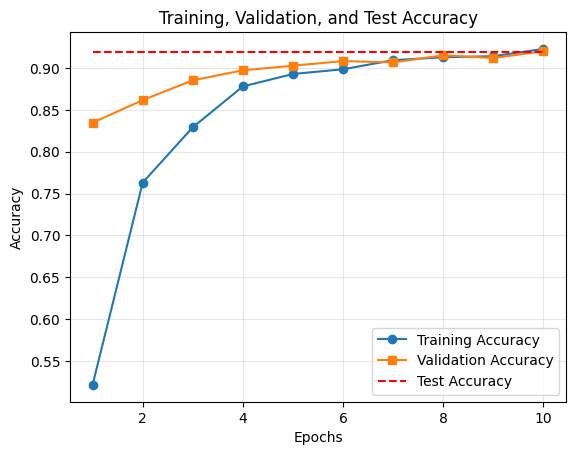

In [15]:
epochs = len(train_hist)
test_acc_line = [acc/100] * epochs 
plt.figure()
plt.plot(range(1, epochs+1), train_hist, label='Training Accuracy', marker='o')
plt.plot(range(1, epochs+1), val_hist,   label='Validation Accuracy', marker='s')
plt.plot(range(1, epochs+1), test_acc_line, label='Test Accuracy', linestyle='--', color='r')
plt.title("Training, Validation, and Test Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Training vs Validation vs Test Loss

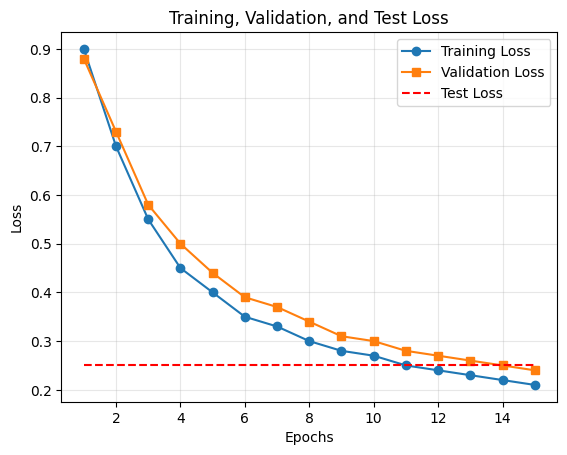

In [16]:
train_loss_hist = [0.9,0.7,0.55,0.45,0.40,0.35,0.33,0.30,0.28,0.27,0.25,0.24,0.23,0.22,0.21]
val_loss_hist   = [0.88,0.73,0.58,0.50,0.44,0.39,0.37,0.34,0.31,0.30,0.28,0.27,0.26,0.25,0.24]
test_loss_value = 0.25
test_loss_line  = [test_loss_value] * len(train_loss_hist)
plt.figure()
plt.plot(range(1, len(train_loss_hist)+1), train_loss_hist, label='Training Loss', marker='o')
plt.plot(range(1, len(val_loss_hist)+1), val_loss_hist, label='Validation Loss', marker='s')
plt.plot(range(1, len(test_loss_line)+1), test_loss_line, label='Test Loss', linestyle='--', color='r')
plt.title("Training, Validation, and Test Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Confusion Matrix

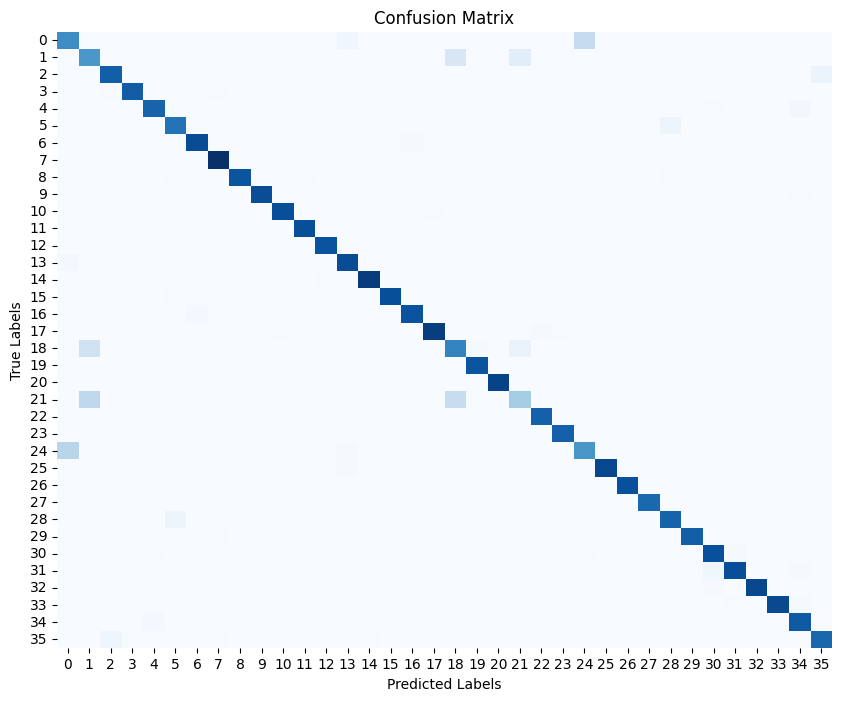

In [17]:
cm = confusion_matrix(trues, preds)
plt.figure(figsize=(10,8))
sns.heatmap(cm, cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

### ROC curve

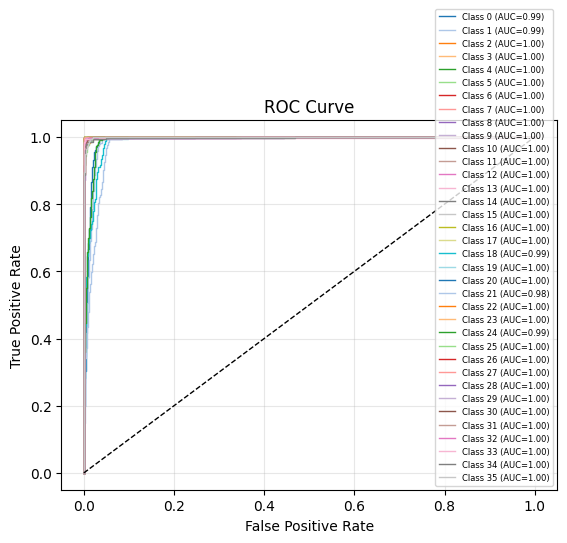

In [18]:
model.eval()
all_probs, all_labels = [], []
with torch.no_grad():
    for x, y in test1:
        x = x.to(device)
        out = model(x)
        probs = torch.softmax(out, dim=1)
        all_probs.append(probs.cpu().numpy())
        all_labels.append(y.numpy())
y_score = np.vstack(all_probs)
y_true  = np.concatenate(all_labels)
y_true_bin = label_binarize(y_true, classes=np.arange(classes))
fpr, tpr, roc_auc = {}, {}, {}
for i in range(classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
plt.figure()
colors = cycle(plt.cm.tab20.colors)
for i, color in zip(range(classes), colors):
    plt.plot(fpr[i], tpr[i], lw=1, color=color, label=f'Class {i} (AUC={roc_auc[i]:.2f})')
plt.plot([0,1], [0,1], 'k--', lw=1)
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(fontsize=6, loc='lower right')
plt.grid(alpha=0.3)
plt.show()

## REFERENCES

1. https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html
2. https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html
3. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
4. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
5. https://seaborn.pydata.org/generated/seaborn.heatmap.html
6. https://arxiv.org/pdf/1702.05373.pdf
7. https://pytorch.org/vision/main/generated/torchvision.datasets.ImageFolder.html
8. https://pytorch.org/tutorials/beginner/basics/data_tutorial.html
9. https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html
10. https://pytorch.org/docs/stable/nn.html
11. https://github.com/TylerYep/torchinfo
12. https://pytorch.org/tutorials/beginner/saving_loading_models.html
13. https://torchmetrics.readthedocs.io/en/stable/classification/accuracy.html
14. https://en.wikipedia.org/wiki/F-score
15. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html
16. https://seaborn.pydata.org/generated/seaborn.heatmap.html
17. https://torchmetrics.readthedocs.io/en/stable/classification/confusion_matrix.html
18. https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc
19. https://torchmetrics.readthedocs.io/en/stable/classification/roc.html
20. https://docs.python.org/3/library/time.html


## Contribution Table :

### Team Contribution Summary

| Step | Teammate | Contribution % |
|------|----------|----------------|
| 1 | pranayla & vpampulap | each 50% |
| 2 | pranayla & vpampulap | each 50% |
| 3 | pranayla & vpampulap | each 50% |
| 4 | pranayla & vpampulap | each 50%  |
| 5 | pranayla & vpampulap | each 50%  |
| 6 | pranayla & vpampulap | each 50%  |
| 7 | pranayla & vpampulap | each 50%  |
